# STATS 425 · Week 8 lab
**Uncertainty without retraining**  
**TA:** Ali Kaazempur-Mofrad

In Week 6, we trained a policy to report a confidence $q$ along with its answer, using the calibration reward $c-(q-c)^2$. Often we cannot retrain a model: its weights are fixed, or training is too expensive. Today, we start from a **fixed model** and work only with its outputs. We measure how confident it is, check and correct its calibration, return sets of answers with a coverage guarantee, and decide when it should decline to answer. Week 1's log loss and Week 3's temperature both return in new roles.

**How this maps to a language model.** Our "model" is a simulation of a fixed system that answers multiple-choice questions with five options, A–E. For a language model, the five probabilities could be the next-token probabilities of the answer letters after the question (as in Week 1), and sampled answers could come from generating several responses (as in Week 3). Every method today uses only these outputs and a set of questions with known answers. None of them changes the model's weights.

| Section | Question we answer |
|---|---|
| 1. Two ways to measure confidence | How sure is the model, and can sampled answers tell us without its probabilities? |
| 2. Checking and fixing calibration | Do the model's probabilities match its accuracy, and can one number fix them? |
| 3. Conformal prediction sets | How can we return a set of answers that contains the correct one at least 90% of the time? |
| 4. Answer or abstain | When should the model decline to answer, so that the answers it gives are rarely wrong? |
| 5. Try it: change the model and the targets | How do overconfidence, $\alpha$, and $\varepsilon$ change the results? |

**Set up the notebook.** The cell below imports the libraries and sets a random seed so the results are repeatable; exact numbers may differ slightly across PyTorch versions.

In [1]:
import importlib.util
import subprocess
import sys

if importlib.util.find_spec("torch") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "torch>=2.8,<3"])

import math

import matplotlib.pyplot as plt
import torch

SEED = 425
torch.manual_seed(SEED)
torch.set_num_threads(1)
# Double precision keeps probabilities very close to 1 distinguishable from each other.
torch.set_default_dtype(torch.float64)

BLUE, RED, GRAY = "#2874A6", "#C0392B", "#7F8C8D"
print(f"Setup complete. PyTorch {torch.__version__}")

Setup complete. PyTorch 2.8.0+cu128


## 1 · Two ways to measure confidence

**Simulate a fixed model.** We want to know the truth about every question so we can check each method, so we simulate a model instead of loading one. Each question has $K=5$ candidate answers labeled A–E, one true answer $y$, and a **difficulty** $d$ between 0 (easy) and 1 (hard), drawn uniformly at random. The model computes one logit for each answer $k$:

$$
z_k=\kappa\Big(a\,(1-d)\,\mathbf{1}\{k=y\}+\xi_k\Big),
\qquad \xi_k\sim\mathcal{N}(0,1)\ \text{independently},
\qquad k=1,\ldots,K.
$$

- $a(1-d)$ is the **evidence** for the true answer. With $a=4$, the evidence is strong for easy questions and zero for the hardest ones, where the model can only guess.
- $\xi_k$ is random noise, different for each question and answer.
- $\kappa=3$ is an **overconfidence factor**. Multiplying every logit by $\kappa>1$ pushes the probabilities toward 0 and 1, so the model sounds more certain, without changing which answer it ranks first. Guo et al. (2017) found that many modern neural networks are overconfident, and that dividing their logits by a single number largely corrects this.

As in Week 3, softmax turns logits into probabilities, $\hat p_k(x)=e^{z_k}/\sum_{j=1}^{K}e^{z_j}$. The model's answer is its most likely option, $\hat y(x)=\arg\max_k \hat p_k(x)$.

We draw a **calibration set** of $n=1000$ questions and a separate **test set** of 2000 questions. The calibration set plays the role of a modest labeled data set that we may use to adjust how we read the model's outputs; the test set checks the result on new questions. The methods never see the difficulty $d$; we use it only to examine results.

**Two measures of confidence.**

- **Top probability:** $q(x)=\max_k \hat p_k(x)$, the probability the model gives its own answer. This requires access to the model's probabilities.
- **Agreement among sampled answers:** sample $m$ answers at temperature 1 (Week 3), find the most common one, and record the fraction of samples that agree with it, $\tilde q_m(x)=\max_k \#\{\text{samples equal to }k\}/m$. This requires only the ability to sample, as with many chat interfaces. Wang et al. (2022) call the majority vote over sampled answers **self-consistency**.

**Create the questions and inspect one.** The cell below simulates both sets, then shows one test question: its five probabilities, ten sampled answers, and both confidence measures. Sampling uses its own random generator, so the questions themselves do not depend on how many answers we sample.

In [2]:
K = 5
LETTERS = ("A", "B", "C", "D", "E")
EVIDENCE = 4.0        # a: evidence for the true answer on the easiest questions
OVERCONFIDENCE = 3.0  # kappa: multiplies every logit
N_CAL, N_TEST = 1000, 2000


def make_questions(n, generator, overconfidence=OVERCONFIDENCE):
    difficulty = torch.rand(n, generator=generator)
    answers = torch.randint(K, (n,), generator=generator)
    evidence = torch.randn(n, K, generator=generator)
    evidence[torch.arange(n), answers] += EVIDENCE * (1 - difficulty)
    return {"logits": overconfidence * evidence, "answers": answers, "difficulty": difficulty}


def top_answer(logits):
    probabilities = torch.softmax(logits, dim=1)
    confidence, prediction = probabilities.max(dim=1)
    return probabilities, confidence, prediction


def sample_answers(logits, m, generator):
    # m answers per question, drawn from softmax(logits) at temperature 1.
    return torch.multinomial(torch.softmax(logits, dim=1), m, replacement=True, generator=generator)


def agreement(samples):
    counts = torch.nn.functional.one_hot(samples, K).sum(dim=1)
    top_count, majority = counts.max(dim=1)
    return top_count / samples.shape[1], majority


data_generator = torch.Generator().manual_seed(SEED)
calibration = make_questions(N_CAL, data_generator)
test = make_questions(N_TEST, data_generator)
sample_generator = torch.Generator().manual_seed(SEED + 1)

test_probs, test_conf, test_pred = top_answer(test["logits"])
test_correct = test_pred == test["answers"]

# Show the first test question whose top probability is between 0.55 and 0.8.
i = int(torch.nonzero((test_conf > 0.55) & (test_conf < 0.8))[0])
example_samples = sample_answers(test["logits"][i:i + 1], 10, sample_generator)
example_agreement, example_majority = agreement(example_samples)

print(f"TEST QUESTION {i} | difficulty d = {test['difficulty'][i].item():.2f}"
      f" | true answer: {LETTERS[test['answers'][i]]}")
print(f"{'Answer':<8}{'Logit':>9}{'Probability':>14}")
for k in range(K):
    print(f"{LETTERS[k]:<8}{test['logits'][i, k].item():>9.2f}{test_probs[i, k].item():>14.4f}")
print("-" * 52)
print("Ten sampled answers: " + " ".join(LETTERS[s] for s in example_samples[0].tolist()))
print(f"Top probability q(x):       {test_conf[i].item():.2f} (answer {LETTERS[test_pred[i]]})")
print(f"Agreement of 10 samples:    {example_agreement.item():.2f} (majority {LETTERS[example_majority]})")
print("=" * 52)
print(f"Test set: {N_TEST} questions | accuracy of top answer: {test_correct.double().mean():.1%}"
      f" | average top probability: {test_conf.mean():.3f}")

TEST QUESTION 2 | difficulty d = 0.21 | true answer: D
Answer      Logit   Probability
A            1.49        0.0357
B            2.32        0.0819
C            2.60        0.1080
D            4.52        0.7390
E            1.48        0.0354
----------------------------------------------------
Ten sampled answers: D D D D C C D D D D
Top probability q(x):       0.74 (answer D)
Agreement of 10 samples:    0.80 (majority D)
Test set: 2000 questions | accuracy of top answer: 70.5% | average top probability: 0.860


Read the example from top to bottom: the logits, their softmax probabilities, then ten answers sampled from those probabilities. The fraction of samples equal to the model's top answer would be an unbiased estimate of $q(x)$, because each sample matches that answer with probability $q(x)$. Agreement uses the most common sampled answer instead, which is usually the top answer, so it is a noisy and slightly upward-biased estimate of $q(x)$.

The last line already hints at a problem. On average, the model gives its answer a probability well above the fraction of answers that are correct.

**Check calibration with a reliability table.** As in Week 6, a model is **calibrated** if, among answers given with confidence about 0.8, about 80% are correct. We group test questions into ten confidence **bins** of width 0.1 ($[0,0.1)$, $[0.1,0.2)$, ..., $[0.9,1]$). In each bin $b$, we compare the average confidence $\mathrm{conf}_b$ with the accuracy $\mathrm{acc}_b$. The **expected calibration error (ECE)** averages the gaps, weighting each bin by its share $n_b/n$ of the questions:

$$
\mathrm{ECE}=\sum_{b}\frac{n_b}{n}\,\big|\mathrm{acc}_b-\mathrm{conf}_b\big|.
$$

A perfectly calibrated model has ECE near 0 on a large test set. ECE depends on the choice of bins and has sampling noise, so treat it as a summary rather than an exact quantity. With five answers, the top probability is at least $1/5$, so the lowest bins stay empty.

**Predict before running:** sampling adds randomness. Do you expect agreement among $m=10$ samples to be better or worse calibrated than the top probability?

The cell prints both reliability tables, their ECEs, and a small table showing how agreement changes as the number of samples $m$ grows. The plot shows each bin as a point (average confidence, accuracy); a calibrated model lies on the dashed diagonal.

TOP PROBABILITY q(x)
Bin            Questions  Avg confidence  Accuracy     Gap
[0.2, 0.3)             2           0.274     0.500  +0.226
[0.3, 0.4)            28           0.372     0.321  -0.051
[0.4, 0.5)           107           0.461     0.318  -0.144
[0.5, 0.6)           132           0.553     0.447  -0.106
[0.6, 0.7)           149           0.657     0.403  -0.255
[0.7, 0.8)           154           0.752     0.500  -0.252
[0.8, 0.9)           229           0.855     0.559  -0.296
[0.9, 1.0]          1199           0.982     0.869  -0.113
ECE = 0.156

AGREEMENT OF m = 10 SAMPLES (scored against the majority answer)
Bin            Questions  Avg confidence  Accuracy     Gap
[0.3, 0.4)             6           0.300     0.000  -0.300
[0.4, 0.5)            56           0.400     0.232  -0.168
[0.5, 0.6)           123           0.500     0.285  -0.215
[0.6, 0.7)           143           0.600     0.378  -0.222
[0.7, 0.8)           150           0.700     0.533  -0.167
[0.8, 0.9)      

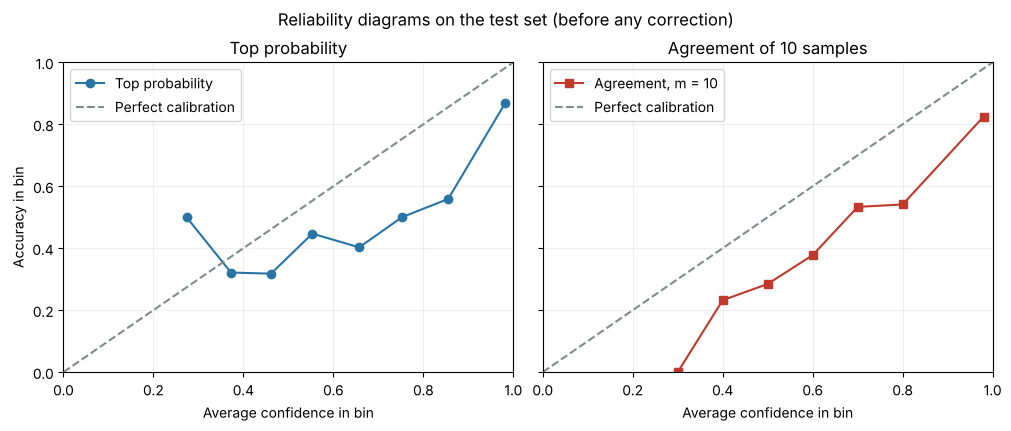

In [3]:
NUM_BINS = 10


def reliability_table(confidence, correct, num_bins=NUM_BINS):
    # Bin b holds confidences in [b/num_bins, (b+1)/num_bins); the last bin also holds 1.0.
    bins = torch.clamp((confidence * num_bins + 1e-9).floor().long(), max=num_bins - 1)
    rows = []
    for b in range(num_bins):
        in_bin = bins == b
        if in_bin.any():
            rows.append({"low": b / num_bins, "high": (b + 1) / num_bins, "count": int(in_bin.sum()),
                         "confidence": confidence[in_bin].mean().item(),
                         "accuracy": correct[in_bin].double().mean().item()})
    return rows


def expected_calibration_error(confidence, correct, num_bins=NUM_BINS):
    rows = reliability_table(confidence, correct, num_bins)
    return sum(r["count"] / len(confidence) * abs(r["accuracy"] - r["confidence"]) for r in rows)


def print_reliability(name, confidence, correct):
    print(name)
    print(f"{'Bin':<14}{'Questions':>10}{'Avg confidence':>16}{'Accuracy':>10}{'Gap':>8}")
    for r in reliability_table(confidence, correct):
        closing = "]" if r["high"] == 1.0 else ")"  # the last bin includes 1.0
        label = f"[{r['low']:.1f}, {r['high']:.1f}{closing}"
        print(f"{label:<14}{r['count']:>10}{r['confidence']:>16.3f}{r['accuracy']:>10.3f}"
              f"{r['accuracy'] - r['confidence']:>+8.3f}")
    print(f"ECE = {expected_calibration_error(confidence, correct):.3f}\n")


M_SAMPLES = 10
test_samples = sample_answers(test["logits"], M_SAMPLES, sample_generator)
test_agree, test_majority = agreement(test_samples)
majority_correct = test_majority == test["answers"]

print_reliability("TOP PROBABILITY q(x)", test_conf, test_correct)
print_reliability(f"AGREEMENT OF m = {M_SAMPLES} SAMPLES (scored against the majority answer)",
                  test_agree, majority_correct)

print(f"{'Samples m':<11}{'Avg agreement':>15}{'Avg top prob':>14}{'Avg |difference|':>18}{'Majority acc':>14}")
for m in (3, 10, 40):
    agree_m, majority_m = agreement(sample_answers(test["logits"], m, sample_generator))
    print(f"{m:<11}{agree_m.mean().item():>15.3f}{test_conf.mean().item():>14.3f}"
          f"{(agree_m - test_conf).abs().mean().item():>18.3f}"
          f"{(majority_m == test['answers']).double().mean().item():>14.1%}")


def plot_reliability(ax, confidence, correct, color, label, marker="o"):
    rows = reliability_table(confidence, correct)
    ax.plot([r["confidence"] for r in rows], [r["accuracy"] for r in rows],
            marker=marker, color=color, label=label)


fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), sharey=True, constrained_layout=True)
plot_reliability(axes[0], test_conf, test_correct, BLUE, "Top probability")
plot_reliability(axes[1], test_agree, majority_correct, RED, f"Agreement, m = {M_SAMPLES}", marker="s")
for ax, title in zip(axes, ["Top probability", f"Agreement of {M_SAMPLES} samples"]):
    ax.plot([0, 1], [0, 1], linestyle="--", color=GRAY, label="Perfect calibration")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_title(title)
    ax.set_xlabel("Average confidence in bin")
    ax.grid(alpha=0.2)
    ax.legend(loc="upper left")
axes[0].set_ylabel("Accuracy in bin")
fig.suptitle("Reliability diagrams on the test set (before any correction)")
plt.show()

**Both measures are overconfident.** In almost every bin, accuracy falls below the average confidence, so both curves lie mostly below the diagonal. The largest bin, confidence 0.9 or more, has an average confidence near 0.98 but an accuracy below 0.9. (Bins with only a few questions, such as the lowest one, are too small to read much into.)

**Agreement does not fix this.** Agreement estimates the top probability. With few samples, the estimate is coarse (multiples of $1/m$) and, on average, slightly *higher* than $q(x)$: the most common answer in a small sample tends to look more popular than it really is. As $m$ grows, the average difference shrinks and agreement approaches the top probability, inheriting the same overconfidence. Sampling cannot reveal information that the probabilities do not already contain. The majority answer is about as accurate as the top answer.

**Answer to the prediction.** In this run, agreement among 10 samples is slightly *worse* calibrated than the top probability: its ECE is 0.174, compared with 0.156 for the top probability.

So why use agreement? It needs **only samples**, which is often all we can get from a language model. When a model reasons step by step before answering, the probability of the final answer is not a single softmax, and the agreement among several sampled responses is a natural confidence estimate. Wang et al. (2022) report that answers with higher agreement tend to be more accurate. Whether that confidence is calibrated must still be checked, which is the next section.

## 2 · Checking and fixing calibration

We cannot change the model, but we can change **how we turn its logits into probabilities**. **Temperature scaling** (Guo et al., 2017) divides every logit by one number $T>0$ before softmax:

$$
\hat p_k^{(T)}(x)=\frac{e^{z_k/T}}{\sum_{j=1}^{K}e^{z_j/T}}.
$$

This is Week 3's temperature, now used to adjust the reported probabilities rather than to sample text. $T>1$ flattens the probabilities (less confident); $T<1$ sharpens them. Dividing all logits of a question by the same positive $T$ keeps their order, so **the top answer and the accuracy do not change**; only the confidence does.

**Choose $T$ with Week 1's log loss.** We pick the temperature that minimizes the average negative log-likelihood (NLL) of the true answers on the calibration set:

$$
\mathrm{NLL}(T)=-\frac{1}{n}\sum_{i=1}^{n}\ln \hat p^{(T)}_{y_i}(x_i).
$$

This is exactly Week 1's mean loss, with the "observed token" replaced by the true answer. The log score is a proper scoring rule (Week 6): it rewards honest probabilities. Minimizing it over $T$ therefore favors the temperature whose probabilities best match how often answers are actually correct, within this one-parameter family. We optimize $\ln T$ rather than $T$, so that $T$ stays positive, using Adam as in Weeks 4–7. There is only one parameter, and the model's weights stay fixed.

**Use a separate calibration set.** We fit $T$ on the calibration set and evaluate on the test set. Fitting and evaluating on the same questions would make the corrected probabilities look better than they will be on new questions.

**Predict before running:** for an overconfident model, should $\hat T$ be above or below 1? What will happen to the test accuracy?

The cell fits $T$, prints NLL, accuracy, average confidence, and ECE before and after, and plots the NLL curve and the reliability diagram before and after.

Fitted temperature on the calibration set: T_hat = 2.305

Quantity                                   T = 1    T = 2.30
------------------------------------------------------------
Calibration NLL (fitting loss)             1.086       0.804
Test NLL                                   1.088       0.814
Test accuracy                              70.5%       70.5%
Test average confidence                    0.860       0.694
Test ECE                                   0.156       0.027
Top answers that changed: 0 of 2000

TEST SET AFTER TEMPERATURE SCALING (T = 2.30)
Bin            Questions  Avg confidence  Accuracy     Gap
[0.2, 0.3)            16           0.275     0.188  -0.088
[0.3, 0.4)           193           0.354     0.358  +0.003
[0.4, 0.5)           280           0.452     0.446  -0.006
[0.5, 0.6)           272           0.551     0.500  -0.051
[0.6, 0.7)           222           0.648     0.662  +0.014
[0.7, 0.8)           230           0.749     0.774  +0.025
[0.8, 0.9)         

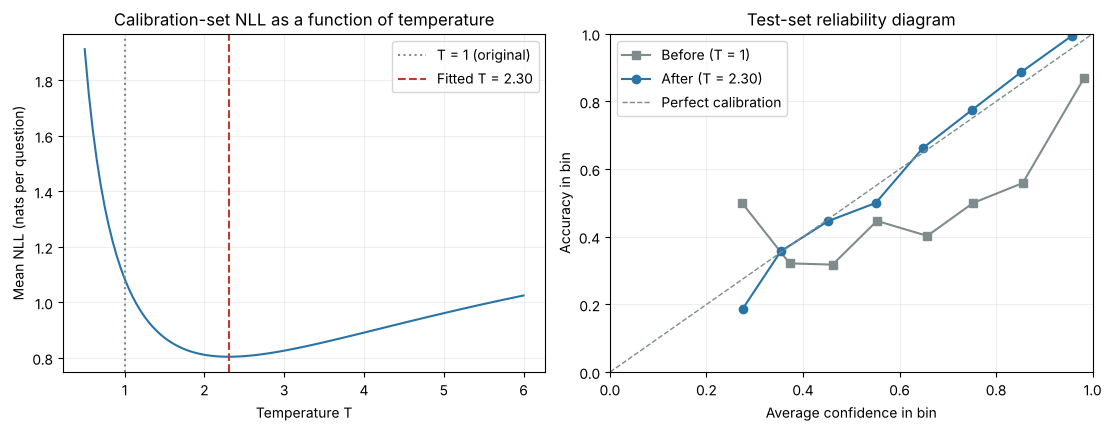

In [4]:
def mean_nll(logits, answers, temperature=1.0):
    log_probs = torch.log_softmax(logits / temperature, dim=1)
    return -log_probs[torch.arange(len(answers)), answers].mean()


def fit_temperature(logits, answers, steps=300, learning_rate=0.05):
    log_t = torch.zeros(1, requires_grad=True)  # start at T = 1
    optimizer = torch.optim.Adam([log_t], lr=learning_rate)
    for _ in range(steps):
        loss = mean_nll(logits, answers, log_t.exp())
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    return log_t.exp().item()


T_hat = fit_temperature(calibration["logits"], calibration["answers"])

_, scaled_conf, scaled_pred = top_answer(test["logits"] / T_hat)
scaled_correct = scaled_pred == test["answers"]

print(f"Fitted temperature on the calibration set: T_hat = {T_hat:.3f}\n")
print(f"{'Quantity':<36}{'T = 1':>12}{f'T = {T_hat:.2f}':>12}")
print("-" * 60)
with torch.no_grad():
    print(f"{'Calibration NLL (fitting loss)':<36}{mean_nll(calibration['logits'], calibration['answers']).item():>12.3f}"
          f"{mean_nll(calibration['logits'], calibration['answers'], T_hat).item():>12.3f}")
    print(f"{'Test NLL':<36}{mean_nll(test['logits'], test['answers']).item():>12.3f}"
          f"{mean_nll(test['logits'], test['answers'], T_hat).item():>12.3f}")
print(f"{'Test accuracy':<36}{test_correct.double().mean().item():>12.1%}{scaled_correct.double().mean().item():>12.1%}")
print(f"{'Test average confidence':<36}{test_conf.mean().item():>12.3f}{scaled_conf.mean().item():>12.3f}")
print(f"{'Test ECE':<36}{expected_calibration_error(test_conf, test_correct):>12.3f}"
      f"{expected_calibration_error(scaled_conf, scaled_correct):>12.3f}")
print(f"Top answers that changed: {(scaled_pred != test_pred).sum().item()} of {N_TEST}\n")
print_reliability(f"TEST SET AFTER TEMPERATURE SCALING (T = {T_hat:.2f})", scaled_conf, scaled_correct)

temperatures = torch.linspace(0.5, 6.0, 111)
with torch.no_grad():
    nll_curve = [mean_nll(calibration["logits"], calibration["answers"], t).item() for t in temperatures]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), constrained_layout=True)
axes[0].plot(temperatures, nll_curve, color=BLUE)
axes[0].axvline(1.0, color=GRAY, linestyle=":", label="T = 1 (original)")
axes[0].axvline(T_hat, color=RED, linestyle="--", label=f"Fitted T = {T_hat:.2f}")
axes[0].set_title("Calibration-set NLL as a function of temperature")
axes[0].set_xlabel("Temperature T")
axes[0].set_ylabel("Mean NLL (nats per question)")
axes[0].legend()
axes[0].grid(alpha=0.2)

plot_reliability(axes[1], test_conf, test_correct, GRAY, "Before (T = 1)", marker="s")
plot_reliability(axes[1], scaled_conf, scaled_correct, BLUE, f"After (T = {T_hat:.2f})")
axes[1].plot([0, 1], [0, 1], linestyle="--", color=GRAY, linewidth=1, label="Perfect calibration")
axes[1].set_xlim(0, 1)
axes[1].set_ylim(0, 1)
axes[1].set_title("Test-set reliability diagram")
axes[1].set_xlabel("Average confidence in bin")
axes[1].set_ylabel("Accuracy in bin")
axes[1].legend(loc="upper left")
axes[1].grid(alpha=0.2)
plt.show()

**$\hat T$ is above 1**, so temperature scaling softens the overconfident probabilities. The NLL curve has a single minimum at the fitted temperature, and the test NLL also falls, so the improvement carries over to new questions.

**Accuracy is unchanged** and no top answer changed, as expected: dividing logits by a positive number does not reorder them. The average confidence falls toward the accuracy, the test ECE drops substantially, and the reliability points move close to the diagonal.

<details><summary>Why is $\hat T$ not exactly $\kappa=3$, and why is ECE not exactly 0?</summary>

Dividing by $\kappa$ would undo the overconfidence factor, but the remaining logits $a(1-d)\mathbf{1}\{k=y\}+\xi_k$ are not calibrated either. The honest amount of confidence depends on the difficulty $d$, which the model does not see. One temperature can only find the best compromise across all difficulties, so some groups of questions can remain somewhat over- or underconfident. The test ECE also has sampling noise from a finite number of questions per bin.

</details>

**Discuss:** temperature scaling made the confidence trustworthy *on average over questions like these*. What could go wrong if next month's questions are harder than the calibration questions?

## 3 · Conformal prediction sets

Calibration is a statement about averages within confidence bins. Sometimes we want a direct guarantee instead: **return a set of answers that contains the correct one with probability at least $1-\alpha$**, for example 90% when $\alpha=0.1$. When the model is sure, the set can be a single answer; when it is unsure, the set should be larger. **Split conformal prediction** (Angelopoulos and Bates, 2021) does this with a fixed model and a calibration set, without retraining.

**1. Score the calibration questions.** For each calibration question $i$, compute the **nonconformity score**

$$
s_i=1-\hat p_{y_i}(x_i),
$$

one minus the probability the model gave the **true** answer. A small score means the model gave the true answer high probability.

**2. Find the threshold.** Sort the $n$ scores and let $\hat q$ be the $\lceil (n+1)(1-\alpha)\rceil$-th smallest. (If this rank exceeds $n$, set $\hat q=1$ and include every answer.) With $n=1000$ and $\alpha=0.1$, the rank is $\lceil 1001\times0.9\rceil=\lceil 900.9\rceil=901$. Angelopoulos and Bates call this threshold $\hat q$ because it is a quantile of the scores; it is not a confidence $q$.

**3. Form the prediction set.** For a new question $x$, include every answer whose score would be at most the threshold:

$$
C(x)=\{k:\ 1-\hat p_k(x)\le\hat q\}=\{k:\ \hat p_k(x)\ge 1-\hat q\}.
$$

**The guarantee.** If the calibration questions and the test question are **exchangeable** (for example, drawn independently from the same distribution), then

$$
P\big(y_{\text{test}}\in C(x_{\text{test}})\big)\ge 1-\alpha.
$$

The probability is over the random calibration set and the random test question together. It is an **average** guarantee: it does not promise 90% coverage for every individual question, for every kind of question, or for every particular calibration set. It does not require the model's probabilities to be calibrated. We use the original (temperature 1) probabilities here, overconfident as they are.

<details><summary>Why the rank $\lceil (n+1)(1-\alpha)\rceil$?</summary>

Treat the test question's score $s_{\text{test}}=1-\hat p_{y_{\text{test}}}(x_{\text{test}})$ as an $(n+1)$-th score. By exchangeability, its rank among all $n+1$ scores is equally likely to be any of $1,\ldots,n+1$ (assume no ties for simplicity). The true answer is in the set exactly when $s_{\text{test}}\le\hat q$, the $r$-th smallest calibration score, which happens when the test score's rank is at most $r$. That has probability $r/(n+1)$. Choosing $r=\lceil (n+1)(1-\alpha)\rceil$ makes this at least $1-\alpha$. When the scores have no ties, coverage is also at most $1-\alpha+1/(n+1)$, so the sets are not much larger than necessary on average.

Why not use the temperature-scaled probabilities? We fitted $\hat T$ on these same calibration questions, so scores computed with $\hat T$ would no longer be exchangeable with the test score in the simple sense above. To combine the two, fit $T$ on a separate part of the labeled data.

</details>

The cell computes $\hat q$ for $\alpha\in\{0.05,0.1,0.2\}$, then reports test-set coverage (the fraction of sets that contain the true answer), the average set size, and the fraction of sets with exactly one answer. It also shows the 90% sets for three test questions of increasing difficulty.

In [5]:
ALPHAS = (0.05, 0.10, 0.20)


def conformal_threshold(scores, alpha):
    n = len(scores)
    # Subtract a tiny amount so rounding (e.g. 900.0000000000001) cannot add 1 to the rank.
    rank = math.ceil((n + 1) * (1 - alpha) - 1e-9)
    if rank > n:
        return 1.0, rank
    return scores.sort().values[rank - 1].item(), rank


def prediction_sets(probabilities, q_hat):
    return (1 - probabilities) <= q_hat  # True where an answer is in the set


cal_probs, _, _ = top_answer(calibration["logits"])
cal_scores = 1 - cal_probs[torch.arange(N_CAL), calibration["answers"]]

conformal_results = {}
print(f"{'alpha':<8}{'Rank':>6}{'q_hat':>9}{'Include if p >=':>17}{'Test coverage':>15}{'Avg size':>10}{'Size 1':>9}")
print("-" * 74)
for alpha in ALPHAS:
    q_hat, rank = conformal_threshold(cal_scores, alpha)
    sets = prediction_sets(test_probs, q_hat)
    covered = sets[torch.arange(N_TEST), test["answers"]]
    sizes = sets.sum(dim=1)
    conformal_results[alpha] = {"q_hat": q_hat, "sets": sets, "covered": covered, "sizes": sizes}
    print(f"{alpha:<8.2f}{rank:>6}{q_hat:>9.4f}{1 - q_hat:>17.4f}{covered.double().mean().item():>15.1%}"
          f"{sizes.double().mean().item():>10.2f}{(sizes == 1).double().mean().item():>9.1%}")

print("\nEXAMPLE 90% PREDICTION SETS (alpha = 0.10)")
print(f"{'Question':<10}{'Difficulty':>11}{'Probabilities (A-E)':>36}  {'Set':<12}{'True':>5}")
sets_90 = conformal_results[0.10]["sets"]
for target in (0.1, 0.5, 0.9):
    j = int((test["difficulty"] - target).abs().argmin())
    probs_text = " ".join(f"{p:.2f}" for p in test_probs[j].tolist())
    set_text = "{" + ", ".join(LETTERS[k] for k in range(K) if sets_90[j, k]) + "}"
    print(f"{j:<10}{test['difficulty'][j].item():>11.2f}{probs_text:>36}  {set_text:<12}{LETTERS[test['answers'][j]]:>5}")

alpha     Rank    q_hat  Include if p >=  Test coverage  Avg size   Size 1
--------------------------------------------------------------------------
0.05       951   0.9976           0.0024          96.0%      2.75    28.0%
0.10       901   0.9854           0.0146          91.2%      2.12    42.4%
0.20       801   0.8570           0.1430          79.9%      1.35    71.1%

EXAMPLE 90% PREDICTION SETS (alpha = 0.10)
Question   Difficulty                 Probabilities (A-E)  Set          True
1030             0.10            0.00 0.00 1.00 0.00 0.00  {C}             C
1144             0.50            0.00 0.00 0.01 0.90 0.09  {D, E}          D
882              0.90            0.00 0.01 0.43 0.00 0.56  {C, E}          A


Read the first table row by row. As $\alpha$ falls, the required coverage $1-\alpha$ rises, the rank and the threshold $\hat q$ rise, and the sets include answers with lower probabilities, so the average set size grows. A threshold $\hat q$ close to 1 means that answers with quite small probabilities still enter the set. This is the overconfident model at work: the true answer sometimes receives a very small probability.

Test-set coverage is close to each target $1-\alpha$. A single test set can land a little above or below the target because both the calibration set and the test set are random; we check the average over many repetitions below. The example sets grow with difficulty: the easy question gets a single answer, while the harder ones get several. In the saved output, the hardest example's set misses the true answer, to which the model gave almost no probability. The guarantee allows such misses, as long as they are rare on average.

**Predict before running:** the guarantee is an average over all questions. On the hardest test questions, do you expect coverage above, near, or below 90%?

The next cell groups test questions by their (simulated) difficulty and plots the average set size and the coverage in each group, for the three values of $\alpha$. It then repeats the whole procedure 1000 times with fresh calibration and test sets, to check the guarantee as stated: on average over calibration and test data.

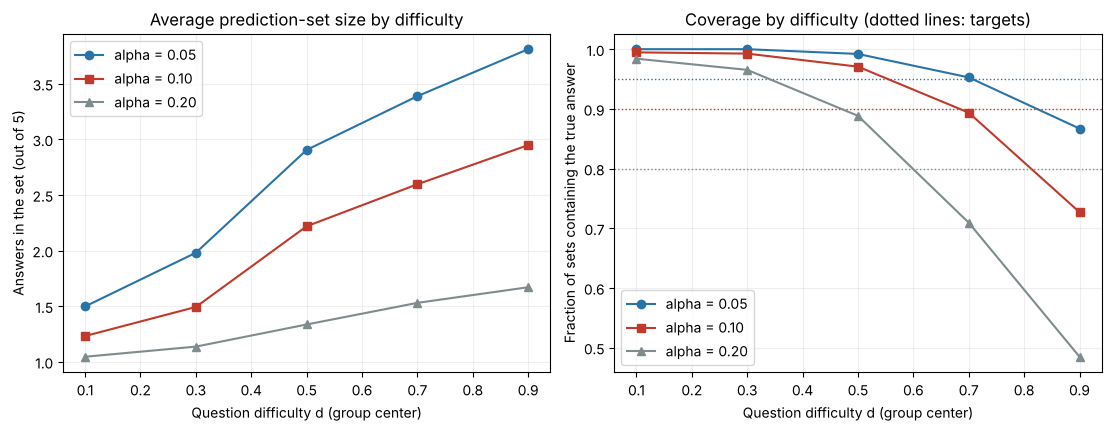

alpha = 0.10, TEST SET BY DIFFICULTY
Difficulty     Questions  Avg set size  Coverage
[0.0, 0.2)           376          1.23     99.5%
[0.2, 0.4)           404          1.49     99.3%
[0.4, 0.6)           376          2.22     97.1%
[0.6, 0.8)           423          2.60     89.4%
[0.8, 1.0)           421          2.95     72.7%
All                 2000          2.12     91.2%



1000 REPETITIONS, alpha = 0.10 (target: at least 90% on average)
Average coverage:                     90.02%
Middle 90% of single-run coverages:   88.0% to 91.9%
Runs with coverage below 90%:         48%


In [6]:
GROUP_EDGES = torch.linspace(0, 1, 6)  # five difficulty groups of width 0.2
group = torch.clamp(torch.bucketize(test["difficulty"], GROUP_EDGES[1:-1], right=True), max=4)
group_centers = ((GROUP_EDGES[:-1] + GROUP_EDGES[1:]) / 2).tolist()

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), constrained_layout=True)
for alpha, color, marker in zip(ALPHAS, (BLUE, RED, GRAY), ("o", "s", "^")):
    res = conformal_results[alpha]
    size_by_group = [res["sizes"][group == g].double().mean().item() for g in range(5)]
    cover_by_group = [res["covered"][group == g].double().mean().item() for g in range(5)]
    axes[0].plot(group_centers, size_by_group, marker=marker, color=color, label=f"alpha = {alpha:.2f}")
    axes[1].plot(group_centers, cover_by_group, marker=marker, color=color, label=f"alpha = {alpha:.2f}")
    axes[1].axhline(1 - alpha, color=color, linestyle=":", linewidth=1)
axes[0].set_title("Average prediction-set size by difficulty")
axes[0].set_ylabel("Answers in the set (out of 5)")
axes[1].set_title("Coverage by difficulty (dotted lines: targets)")
axes[1].set_ylabel("Fraction of sets containing the true answer")
for ax in axes:
    ax.set_xlabel("Question difficulty d (group center)")
    ax.grid(alpha=0.2)
    ax.legend()
plt.show()

res = conformal_results[0.10]
print("alpha = 0.10, TEST SET BY DIFFICULTY")
print(f"{'Difficulty':<14}{'Questions':>10}{'Avg set size':>14}{'Coverage':>10}")
for g in range(5):
    label = f"[{GROUP_EDGES[g].item():.1f}, {GROUP_EDGES[g + 1].item():.1f})"
    print(f"{label:<14}{int((group == g).sum()):>10}{res['sizes'][group == g].double().mean().item():>14.2f}"
          f"{res['covered'][group == g].double().mean().item():>10.1%}")
print(f"{'All':<14}{N_TEST:>10}{res['sizes'].double().mean().item():>14.2f}{res['covered'].double().mean().item():>10.1%}")

# Repeat the whole procedure with fresh calibration and test sets.
repeat_generator = torch.Generator().manual_seed(SEED + 2)
coverages = []
for _ in range(1000):
    cal_r = make_questions(N_CAL, repeat_generator)
    test_r = make_questions(N_TEST, repeat_generator)
    scores_r = 1 - torch.softmax(cal_r["logits"], dim=1)[torch.arange(N_CAL), cal_r["answers"]]
    q_hat_r, _ = conformal_threshold(scores_r, 0.10)
    probs_r = torch.softmax(test_r["logits"], dim=1)
    coverages.append(prediction_sets(probs_r, q_hat_r)[torch.arange(N_TEST), test_r["answers"]].double().mean())
coverages = torch.stack(coverages)
print(f"\n1000 REPETITIONS, alpha = 0.10 (target: at least 90% on average)")
print(f"Average coverage:                     {coverages.mean().item():.2%}")
print(f"Middle 90% of single-run coverages:   {torch.quantile(coverages, 0.05).item():.1%}"
      f" to {torch.quantile(coverages, 0.95).item():.1%}")
print(f"Runs with coverage below 90%:         {(coverages < 0.9).double().mean().item():.0%}")

**Set size grows with difficulty.** Easy questions mostly get one answer; hard questions get larger sets. The set size is an honest signal of how unsure the model is about a question.

**Coverage is not equal across difficulties.** Overall coverage is near 90%, but it is close to 100% for easy questions and well below 90% for the hardest group. The guarantee is **marginal**: it holds on average over all questions, not separately for each kind of question. On the hardest questions the overconfident model can give the true answer a very small probability, so that answer is often left out. Methods that aim for coverage within groups exist (see Angelopoulos and Bates, 2021), but they need the groups to be known in advance and enough calibration questions in each group. Here we could not even form the groups in practice, because the difficulty is not observed.

**The guarantee is about the average over calibration and test data.** Across 1000 repetitions, the average coverage is very close to 90%, as the guarantee predicts. Individual runs scatter around it; roughly half fall a little below 90%, typically by no more than about two percentage points. A single test set, like ours, can therefore land slightly above or below the target without contradicting the guarantee.

## 4 · Answer or abstain

In Weeks 4–6, the policy always answered. A wrong answer earned reward 0 in Week 4, and a penalty that grows with the reported confidence in Week 6. Many applications allow a third option: **abstain**, for example by saying "I am not sure" or passing the question to a person. A simple **selective answering** rule answers only when the top probability is high enough:

$$
\text{answer } \hat y(x) \text{ if } q(x)\ge t,\qquad \text{otherwise abstain}.
$$

Two quantities describe a threshold $t$:

- **Answer rate:** the fraction of questions answered. In the selective-prediction literature this is often called "coverage," which is a different idea from conformal coverage in Section 3.
- **Selective error:** the error rate **among the answered questions**. Write $\mathrm{err}(t)$ for its true value on the whole population of questions.

Raising $t$ usually lowers both: we answer less often, but the answers we give are more often correct.

**Goal.** Choose $t$ from the calibration set so that $\mathrm{err}(t)\le\varepsilon$, with $\varepsilon=0.10$, and so that this claim fails with probability at most $\delta=0.10$. As in Section 3, we assume the calibration questions and future questions are drawn independently from the same distribution.

**Why not just use the calibration error rate?** The error rate among answered calibration questions is only an estimate of $\mathrm{err}(t)$. If we pick the most lenient threshold whose estimate happens to be at most $\varepsilon$, we tend to pick a threshold where the estimate was lucky, and the true error is often above $\varepsilon$.

**Use an upper confidence bound.** At threshold $t$, let $n_t$ be the number of answered calibration questions and $k_t$ the number of those that are wrong. Given $n_t$, each answered question is wrong independently with probability $\mathrm{err}(t)$, so $k_t\sim\mathrm{Binomial}(n_t,\mathrm{err}(t))$. The one-sided **Clopper–Pearson** upper bound $U$ at level $1-\delta$ is the value $u$ that solves

$$
P\big(\mathrm{Binomial}(n_t,u)\le k_t\big)=\sum_{j=0}^{k_t}\binom{n_t}{j}u^j(1-u)^{n_t-j}=\delta,
$$

with $U=1$ if $k_t=n_t$ (or $n_t=0$). In words, $U$ is the largest error rate under which observing as few as $k_t$ errors would not be too surprising. For a single fixed $t$, $P\big(\mathrm{err}(t)\le U\big)\ge 1-\delta$. We find $u$ by bisection, because the left side decreases as $u$ grows. (With SciPy, `scipy.stats.beta.ppf(1 - delta, k + 1, n - k)` gives the same bound.)

**Scan thresholds in a fixed order.** We check thresholds from strictest to most lenient on a grid fixed in advance: $0.999, 0.995, 0.99, 0.98, \ldots, 0.20$. We stop at the first threshold whose bound exceeds $\varepsilon$ and use the last threshold that passed. If even the strictest threshold fails, we abstain on every question.

<details><summary>Why stop at the first failure?</summary>

Checking many thresholds and keeping any one that passes would give chance many opportunities to produce a lucky bound, so the overall error could exceed $\delta$. With a fixed order, consider the first threshold in the sequence whose true error $\mathrm{err}(t)$ is above $\varepsilon$. To end up at that threshold or any later one, the scan must pass that threshold's check, which requires its bound to fall below its true error. That has probability at most $\delta$. So, with probability at least $1-\delta$ over the calibration set, the chosen threshold has $\mathrm{err}(t)\le\varepsilon$. This is called **fixed-sequence testing**.

</details>

**Predict before running:** the naive rule picks the most lenient threshold whose calibration error rate is at most $\varepsilon$. Over many calibration sets, how often do you think its true error exceeds $\varepsilon$: about 10% of the time, about half the time, or almost always?

The first cell plots the test-set trade-off between answer rate and selective error, then runs the scan on the calibration set and checks the chosen threshold on the test set.

SCAN ON THE CALIBRATION SET (epsilon = 0.1, delta = 0.1)
Threshold t   Answered n_t  Errors k_t  Error rate  CP bound U  U <= eps?
0.999                  213           0       0.000       0.011        yes
0.995                  318           7       0.022       0.037        yes
0.990                  372          14       0.038       0.054        yes
0.980                  432          23       0.053       0.070        yes
0.970                  469          30       0.064       0.081        yes
0.960                  497          34       0.068       0.085        yes
0.950                  526          40       0.076       0.093        yes
0.940                  547          46       0.084       0.101   no, stop

Chosen threshold: t = 0.95

Rule                                    t  Cal. answered  Cal. error  Test answered  Test error
-----------------------------------------------------------------------------------------------
Clopper-Pearson, fixed sequence     0.950          52.6%

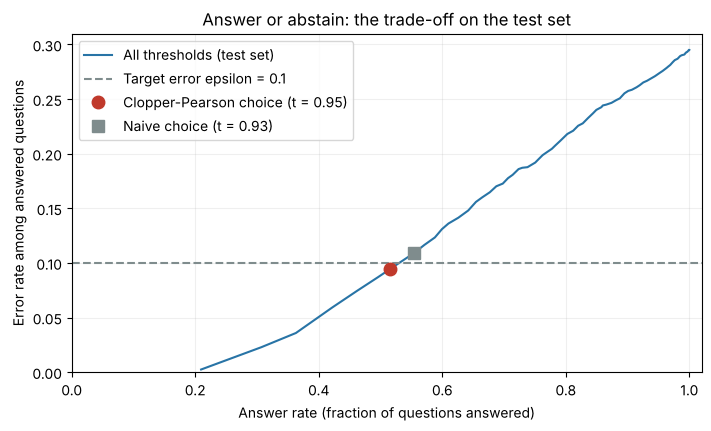

In [7]:
EPSILON, DELTA = 0.10, 0.10
THRESHOLDS = [0.999, 0.995] + [round(0.99 - 0.01 * i, 2) for i in range(80)]  # 0.999, ..., 0.20


def binomial_cdf(k, n, u):
    # P(Binomial(n, u) <= k) for 0 < u < 1; each term is computed on the log scale for accuracy.
    log_n_factorial = math.lgamma(n + 1)
    return sum(math.exp(log_n_factorial - math.lgamma(j + 1) - math.lgamma(n - j + 1)
                        + j * math.log(u) + (n - j) * math.log1p(-u))
               for j in range(k + 1))


def clopper_pearson_upper(k, n, delta, iterations=50):
    if n == 0 or k >= n:
        return 1.0
    low, high = k / n, 1.0  # P(Bin(n, k/n) <= k) >= 1/2 > delta, so the root is above k/n
    for _ in range(iterations):
        middle = (low + high) / 2
        if binomial_cdf(k, n, middle) > delta:
            low = middle
        else:
            high = middle
    return high  # rounding up keeps the bound conservative


def answered_and_errors(confidence, correct, t):
    answered = confidence >= t
    return int(answered.sum()), int((~correct[answered]).sum())


def choose_threshold(confidence, correct, epsilon=EPSILON, delta=DELTA):
    chosen, steps = None, []
    for t in THRESHOLDS:
        n_t, k_t = answered_and_errors(confidence, correct, t)
        bound = clopper_pearson_upper(k_t, n_t, delta)
        steps.append((t, n_t, k_t, bound))
        if bound > epsilon:
            break
        chosen = t
    return chosen, steps


def naive_threshold(confidence, correct, epsilon=EPSILON):
    # The most lenient threshold whose calibration error rate is at most epsilon (no bound).
    chosen = None
    for t in THRESHOLDS:
        n_t, k_t = answered_and_errors(confidence, correct, t)
        if n_t > 0 and k_t <= epsilon * n_t:
            chosen = t
    return chosen


def selective_result(confidence, correct, t):
    if t is None:
        return 0.0, float("nan")
    answered = confidence >= t
    return answered.double().mean().item(), (~correct[answered]).double().mean().item()


_, cal_conf, cal_pred = top_answer(calibration["logits"])
cal_correct = cal_pred == calibration["answers"]

t_chosen, scan = choose_threshold(cal_conf, cal_correct)
t_naive = naive_threshold(cal_conf, cal_correct)

print(f"SCAN ON THE CALIBRATION SET (epsilon = {EPSILON}, delta = {DELTA})")
print(f"{'Threshold t':<13}{'Answered n_t':>13}{'Errors k_t':>12}{'Error rate':>12}{'CP bound U':>12}{'U <= eps?':>11}")
shown = scan if len(scan) <= 8 else scan[:3] + [None] + scan[-4:]  # first and last steps
for row in shown:
    if row is None:
        print(f"{'...':<13}")
        continue
    t, n_t, k_t, bound = row
    print(f"{t:<13.3f}{n_t:>13}{k_t:>12}{k_t / max(n_t, 1):>12.3f}{bound:>12.3f}{'yes' if bound <= EPSILON else 'no, stop':>11}")
print(f"\nChosen threshold: t = {t_chosen}")

print(f"\n{'Rule':<34}{'t':>7}{'Cal. answered':>15}{'Cal. error':>12}{'Test answered':>15}{'Test error':>12}")
print("-" * 95)
for name, t in [("Clopper-Pearson, fixed sequence", t_chosen), ("Naive: calibration error <= eps", t_naive),
                ("Always answer", 0.0)]:
    cal_rate, cal_err = selective_result(cal_conf, cal_correct, t)
    test_rate, test_err = selective_result(test_conf, test_correct, t)
    print(f"{name:<34}{t:>7.3f}{cal_rate:>15.1%}{cal_err:>12.3f}{test_rate:>15.1%}{test_err:>12.3f}")

curve = [selective_result(test_conf, test_correct, t) for t in THRESHOLDS + [0.0]]
fig, ax = plt.subplots(figsize=(7, 4.2), constrained_layout=True)
ax.plot([c[0] for c in curve], [c[1] for c in curve], color=BLUE, label="All thresholds (test set)")
ax.axhline(EPSILON, color=GRAY, linestyle="--", label=f"Target error epsilon = {EPSILON}")
for name, t, color, marker in [("Clopper-Pearson choice", t_chosen, RED, "o"), ("Naive choice", t_naive, GRAY, "s")]:
    rate, err = selective_result(test_conf, test_correct, t)
    ax.plot([rate], [err], marker=marker, markersize=9, color=color, linestyle="none", label=f"{name} (t = {t})")
ax.set_xlim(0, 1.02)
ax.set_ylim(0, None)
ax.set_title("Answer or abstain: the trade-off on the test set")
ax.set_xlabel("Answer rate (fraction of questions answered)")
ax.set_ylabel("Error rate among answered questions")
ax.grid(alpha=0.2)
ax.legend(loc="upper left")
plt.show()

**The trade-off.** Reading the curve from right to left, a stricter threshold answers fewer questions and makes fewer errors among the ones it answers. Answering everything gives the model's full error rate, far above $\varepsilon$.

**The scan.** At the strictest thresholds, the calibration set has few errors and the Clopper–Pearson bound is well below $\varepsilon$. As $t$ falls, more questions are answered, the error rate rises, and the bound eventually exceeds $\varepsilon$, which stops the scan. The bound is always above the observed error rate. That margin is the price of the guarantee, and it shrinks as $n_t$ grows.

**On the test set.** The chosen threshold answers about half of the questions with an error rate at or below $\varepsilon$. The naive rule answers somewhat more questions, but its test error lands above $\varepsilon$ in this run. A single run is only one draw, so the next cell repeats the choice on 200 fresh calibration sets. It measures each chosen threshold's true error $\mathrm{err}(t)$ on 200,000 fresh questions, a stand-in for the whole population.

The raw top probability is overconfident, so the threshold value itself should not be read as "95% sure." The procedure never assumed that $q(x)$ is calibrated. It only needs the confidence to rank questions sensibly and a calibration set to set the threshold.

In [8]:
repeat_generator = torch.Generator().manual_seed(SEED + 3)
population = make_questions(200_000, repeat_generator)
_, pop_conf, pop_pred = top_answer(population["logits"])
pop_correct = pop_pred == population["answers"]

summary = {"Clopper-Pearson, fixed sequence": [], "Naive: calibration error <= eps": []}
for _ in range(200):
    cal_r = make_questions(N_CAL, repeat_generator)
    _, conf_r, pred_r = top_answer(cal_r["logits"])
    correct_r = pred_r == cal_r["answers"]
    for name, t in [("Clopper-Pearson, fixed sequence", choose_threshold(conf_r, correct_r)[0]),
                    ("Naive: calibration error <= eps", naive_threshold(conf_r, correct_r))]:
        summary[name].append(selective_result(pop_conf, pop_correct, t))

print(f"200 CALIBRATION SETS | true error err(t) measured on 200,000 fresh questions | epsilon = {EPSILON}")
print(f"{'Rule':<34}{'Avg answer rate':>17}{'Avg true error':>16}{'Runs with err(t) > eps':>24}")
print("-" * 91)
for name, results in summary.items():
    rates = torch.tensor([r[0] for r in results])
    errors = torch.tensor([r[1] for r in results])
    print(f"{name:<34}{rates.mean().item():>17.1%}{errors.mean().item():>16.3f}"
          f"{(errors > EPSILON).double().mean().item():>24.0%}")

200 CALIBRATION SETS | true error err(t) measured on 200,000 fresh questions | epsilon = 0.1
Rule                                Avg answer rate  Avg true error  Runs with err(t) > eps
-------------------------------------------------------------------------------------------
Clopper-Pearson, fixed sequence               50.1%           0.079                      8%
Naive: calibration error <= eps               54.8%           0.097                     44%


The Clopper–Pearson rule chooses a threshold whose true error exceeds $\varepsilon$ in fewer than $\delta=10\%$ of the calibration sets, as the guarantee promises. The naive rule does so in nearly half of them. It keeps lowering the threshold as long as the calibration error rate stays at or below $\varepsilon$, so it ends near the point where the *estimated* error reaches $\varepsilon$; there, the true error is about as likely to be above $\varepsilon$ as below it. The guarantee costs a somewhat lower answer rate.

**How this maps to a language model.** The confidence $q(x)$ could be the probability of the answer letter, the agreement among sampled responses (Section 1), or a confidence the model states in words (Week 6). Kadavath et al. (2022) found that large language models' probabilities on multiple-choice questions can be fairly well calibrated when the questions are presented in a suitable format, and they studied asking models whether their own answers are correct. Whatever the source, conformal sets and the answer-or-abstain rule only need a held-out set of questions with known answers that resemble future questions.

## 5 · Try it: change the model and the targets

The function below repeats Sections 2–4 in one call for a given overconfidence factor $\kappa$, coverage level $\alpha$, and error target $\varepsilon$. It uses the same random draws for the evidence and noise each time, so only the setting we change differs. With $\kappa=3$, $\alpha=0.1$, and $\varepsilon=0.1$, it reproduces the results above.

**Predict before running:** the next cell compares a mildly overconfident model ($\kappa=2$), our model ($\kappa=3$), and a very overconfident model ($\kappa=6$). As $\kappa$ grows, what happens to

1. the ECE before temperature scaling,
2. the fitted temperature $\hat T$ and the ECE after temperature scaling,
3. the conformal coverage at $\alpha=0.1$, and
4. the chosen threshold $t$ and the test error of the answer-or-abstain rule?

In [9]:
def run_pipeline(overconfidence=3.0, alpha=0.10, epsilon=0.10, delta=0.10, seed=SEED):
    generator = torch.Generator().manual_seed(seed)
    cal = make_questions(N_CAL, generator, overconfidence)
    tst = make_questions(N_TEST, generator, overconfidence)
    _, conf_c, pred_c = top_answer(cal["logits"])
    probs_t, conf_t, pred_t = top_answer(tst["logits"])
    correct_c, correct_t = pred_c == cal["answers"], pred_t == tst["answers"]

    temperature = fit_temperature(cal["logits"], cal["answers"])
    conf_scaled = torch.softmax(tst["logits"] / temperature, dim=1).max(dim=1).values

    scores = 1 - torch.softmax(cal["logits"], dim=1)[torch.arange(N_CAL), cal["answers"]]
    q_hat, _ = conformal_threshold(scores, alpha)
    sets = prediction_sets(probs_t, q_hat)

    t, _ = choose_threshold(conf_c, correct_c, epsilon, delta)
    answer_rate, selective_error = selective_result(conf_t, correct_t, t)
    return {"accuracy": correct_t.double().mean().item(),
            "ece_before": expected_calibration_error(conf_t, correct_t),
            "temperature": temperature,
            "ece_after": expected_calibration_error(conf_scaled, correct_t),
            "coverage": sets[torch.arange(N_TEST), tst["answers"]].double().mean().item(),
            "set_size": sets.sum(dim=1).double().mean().item(),
            "threshold": t, "answer_rate": answer_rate, "selective_error": selective_error}


def print_pipeline_header():
    print(f"{'kappa':>6}{'Acc.':>7}{'ECE before':>12}{'T_hat':>7}{'ECE after':>11}"
          f"{'Coverage':>10}{'Set size':>10}{'t':>7}{'Answered':>10}{'Sel. error':>12}")
    print("-" * 92)


def print_pipeline_row(kappa, r):
    if r["threshold"] is None:  # no threshold passed: abstain on every question
        t_text, error_text = "none", "n/a"
    else:
        t_text, error_text = f"{r['threshold']:.3f}", f"{r['selective_error']:.3f}"
    print(f"{kappa:>6.1f}{r['accuracy']:>7.1%}{r['ece_before']:>12.3f}{r['temperature']:>7.2f}{r['ece_after']:>11.3f}"
          f"{r['coverage']:>10.1%}{r['set_size']:>10.2f}{t_text:>7}{r['answer_rate']:>10.1%}{error_text:>12}")


print("alpha = 0.10, epsilon = 0.10, delta = 0.10")
print_pipeline_header()
for kappa in (2.0, 3.0, 6.0):
    print_pipeline_row(kappa, run_pipeline(overconfidence=kappa))

alpha = 0.10, epsilon = 0.10, delta = 0.10
 kappa   Acc.  ECE before  T_hat  ECE after  Coverage  Set size      t  Answered  Sel. error
--------------------------------------------------------------------------------------------
   2.0  70.5%       0.088   1.54      0.027     90.9%      2.08  0.830     53.6%       0.103


   3.0  70.5%       0.156   2.30      0.027     91.2%      2.12  0.950     51.5%       0.094


   6.0  70.5%       0.225   4.61      0.027     90.6%      2.08  0.999     48.8%       0.086


**Accuracy is the same in every row**, because multiplying all logits by $\kappa>0$ never changes the top answer.

**Calibration.** The ECE before temperature scaling grows with $\kappa$. The fitted temperature grows in proportion to $\kappa$, and the ECE after temperature scaling is the same in every row. Temperature scaling exactly undoes a pure rescaling of the logits, because dividing by $\hat T$ can cancel any constant factor.

**Guarantees.** Conformal coverage stays near 90% for every $\kappa$, and the answer-or-abstain rule keeps the test error near $\varepsilon$ and answers about half of the questions, even for the badly overconfident model. Neither method trusts the probabilities; each sets its threshold from the calibration set. The chosen threshold $t$ rises with $\kappa$, because the same questions receive higher top probabilities. A threshold such as 0.999 is therefore not a statement that the answers are 99.9% likely to be correct.

**Try it:** edit the three values below and predict before running. Suggestions:

- Lower $\alpha$ to 0.02. What happens to the coverage and the average set size?
- Lower $\varepsilon$ to 0.05. How does the answer rate change? What about $\varepsilon=0.01$?
- Set the overconfidence factor to 0.5, an *underconfident* model. Which way should $\hat T$ move? What happens to the answer-or-abstain rule?

In [10]:
YOUR_OVERCONFIDENCE = 3.0  # kappa > 0
YOUR_ALPHA = 0.10          # conformal sets should miss the true answer at most this often
YOUR_EPSILON = 0.10        # target error rate among answered questions

if YOUR_OVERCONFIDENCE <= 0 or not 0 < YOUR_ALPHA < 1 or not 0 < YOUR_EPSILON < 1:
    raise ValueError("Use overconfidence > 0 and alpha, epsilon between 0 and 1.")

result = run_pipeline(YOUR_OVERCONFIDENCE, YOUR_ALPHA, YOUR_EPSILON)
print(f"alpha = {YOUR_ALPHA}, epsilon = {YOUR_EPSILON}, delta = 0.10")
print_pipeline_header()
print_pipeline_row(YOUR_OVERCONFIDENCE, result)

alpha = 0.1, epsilon = 0.1, delta = 0.10
 kappa   Acc.  ECE before  T_hat  ECE after  Coverage  Set size      t  Answered  Sel. error
--------------------------------------------------------------------------------------------
   3.0  70.5%       0.156   2.30      0.027     91.2%      2.12  0.950     51.5%       0.094


<details><summary><b>What to expect:</b> open after trying the suggestions</summary>

- **$\alpha=0.02$:** the rank becomes $\lceil 1001\times0.98\rceil=981$, so $\hat q$ rises, coverage moves up to about 98%, and the sets get larger. Higher coverage costs larger sets.
- **$\varepsilon=0.05$:** the scan stops at a stricter threshold, so the model answers fewer questions (roughly 30% instead of about 50%). With $\varepsilon=0.01$, no threshold passes and the rule abstains on everything. With zero errors among $n$ answered calibration questions, the Clopper–Pearson bound is $1-\delta^{1/n}\approx \ln(1/\delta)/n\approx 2.3/n$. Showing that the error is below 1% would need about 230 answered calibration questions with no errors at all.
- **Overconfidence 0.5:** $\hat T$ falls below 1, so temperature scaling sharpens the probabilities, and the ECE after scaling matches the rows in the table above. Conformal coverage is still near the target. The answer-or-abstain rule now shows `none`: no calibration question reaches the strictest grid threshold, 0.999, so the scan stops at once and the model abstains on every question. This is safe but not useful. Our grid suited an overconfident model; for this model, a grid starting lower would work. The grid must be chosen before seeing the calibration answers. (The same happens for $\kappa=1$, which this simulation makes somewhat underconfident.)

</details>

## Recap

We took a fixed, overconfident model and made its uncertainty useful without changing a single weight:

**Fixed model → probabilities or sampled answers → calibration check → temperature scaling → conformal prediction sets → answer or abstain**

Top probabilities and sample agreement both measure confidence, and both inherited the model's overconfidence. A reliability diagram and ECE revealed the problem. One temperature, fitted with Week 1's log loss on a separate calibration set, corrected most of it without changing any answer. Conformal prediction used the same kind of calibration set to build answer sets with an average coverage guarantee, and a Clopper–Pearson bound with a fixed-sequence scan chose when to abstain so that the error among answered questions stays below a target with high probability.

### Check your understanding

1. Can temperature scaling change a model's accuracy? Why or why not?
2. Why do we fit the temperature on a calibration set rather than on the test set?
3. Suppose 90% conformal sets contain the true answer for 88.5% of a new test set. Does this contradict the guarantee?
4. Why was coverage much lower than 90% on the hardest questions, and does that violate the guarantee?
5. In the answer-or-abstain scan, why do we stop at the first threshold that fails instead of keeping the most lenient threshold that passes?

<details><summary>Answers · open after discussing</summary>

1. No. Dividing all logits of a question by the same $T>0$ keeps their order, so the top answer stays the same. Only the reported probabilities change.
2. Fitting and evaluating on the same questions would make the corrected probabilities look better calibrated than they will be on new questions. The test set must stay untouched to give an honest check.
3. Not by itself. The guarantee says coverage is at least 90% on average over random calibration sets and test questions. One test set is one draw: in our 1000 repetitions, about half of the single runs fell a little below 90%, while the average stayed very close to 90%. A coverage far below the target, or one that stays below it run after run, would suggest that the questions are not exchangeable, for example because new questions differ from the calibration questions.
4. The guarantee is marginal: it averages over all questions. The overconfident model can give the true answer of a hard question a very small probability, so hard questions are covered less often and easy ones more often. This does not violate the guarantee, but it shows its limits.
5. Keeping any threshold that passes would give chance many opportunities to produce a lucky bound. Stopping at the first failure in an order fixed in advance keeps the probability of choosing a threshold with true error above $\varepsilon$ at most $\delta$.

</details>

### Next week: embeddings and retrieval

So far, every lab has worked with probabilities over answers. Next week, we turn to the text-mining side of the course: representing documents as vectors, searching for similar documents, and grouping documents into topics. We then retrieve evidence before answering a question and check, with Week 1's log-probabilities, whether that evidence makes the correct answer more likely.

## References and further reading

- [Guo et al. (2017): On calibration of modern neural networks](https://arxiv.org/abs/1706.04599): reliability diagrams, ECE, and temperature scaling.
- [Wang et al. (2022): Self-consistency improves chain of thought reasoning in language models](https://arxiv.org/abs/2203.11171): agreement among sampled answers.
- [Angelopoulos and Bates (2021): A gentle introduction to conformal prediction](https://arxiv.org/abs/2107.07511): split conformal prediction and coverage guarantees.
- [Kadavath et al. (2022): Language models (mostly) know what they know](https://arxiv.org/abs/2207.05221): calibration of language-model confidence.